# 02 — Preprocesado, features y ventanas

**Objetivo**: convertir las series crudas en tensores listos para PyTorch, y **demostrar** que
el pipeline no filtra información del futuro ni a través de las ventanas ni a través del
escalado.

**Entrada**: `data/interim/` · **Salida**: `data/processed/` (`python -m tfm.data.build_processed`)

Decisiones que se materializan aquí, tomadas en el EDA:

| Decisión | Implementación |
|---|---|
| Huecos ≤ 30 min interpolados, mayores parten la serie | `quality.add_segments` |
| Ninguna ventana cruza un hueco | `windows.make_windows` (itera por segmento) |
| Escalado ajustado solo con train | `windows.WindowScaler` |
| Validación por corte temporal | `windows.temporal_split` |
| Pulsera solo GSR y temp. piel | `features.build_feature_frame(wearable=...)` |

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.data import PATIENTS, quality as q
from tfm.data.datasets import make_loader, patient_windows
from tfm.data.features import (
    FEATURE_COLUMNS, build_feature_frame, carbs_remaining_fraction,
    insulin_remaining_fraction,
)
from tfm.data.loaders import load_cgm
from tfm.data.windows import WindowScaler, concat_windows, temporal_split
from tfm.viz import FIG_WIDTH_FULL, INK, RAMPS, ROLE, add_glycemic_bands, save_figure, set_style

set_style()
pd.set_option("display.width", 150)

## 1. Curvas de decaimiento fisiológico

Una dosis de insulina en su instante exacto es casi inútil como entrada: lo que determina la
glucosa dentro de 30 minutos es **cuánta insulina sigue activa**. Lo mismo con los hidratos.

- **Insulina**: modelo exponencial de actividad (Maksimovic), el que usan los sistemas de
  páncreas artificial abiertos. Se define por dos parámetros interpretables —tiempo al pico y
  duración de acción— lo que lo hace defendible en la memoria frente a un decaimiento *ad hoc*.
  Los 12 pacientes usan Novolog o Humalog, ambos análogos rápidos: **una sola curva cubre
  toda la cohorte** (pico 75 min, duración 300 min).
- **Hidratos**: rampa lineal de 180 min. Deliberadamente más simple, porque la estimación de
  carbohidratos es autorreportada y gruesa; un modelo de absorción elaborado aportaría una
  precisión que la entrada no tiene.

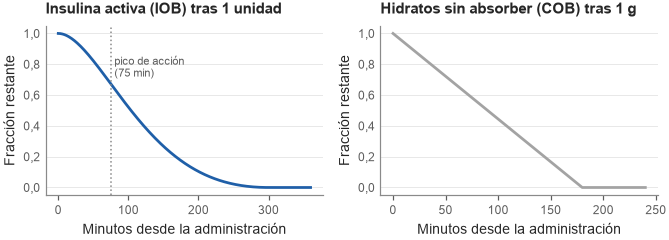

In [2]:
t = np.arange(0, 361, 1.0)
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.4))

axes[0].plot(t, insulin_remaining_fraction(t), color=ROLE["modelo"], lw=1.8)
axes[0].axvline(75, color=INK["tenue"], ls=":", lw=1)
axes[0].annotate("pico de acción\n(75 min)", (80, 0.72), fontsize=7, color=INK["secundario"])
axes[0].set_title("Insulina activa (IOB) tras 1 unidad")
axes[0].set_ylabel("Fracción restante")

axes[1].plot(t[:241], carbs_remaining_fraction(t[:241]), color=ROLE["referencia"], lw=1.8)
axes[1].set_title("Hidratos sin absorber (COB) tras 1 g")
axes[1].set_ylabel("Fracción restante")

for ax in axes:
    ax.set_xlabel("Minutos desde la administración")
fig.tight_layout()
save_figure(fig, "02_curvas_iob_cob")
plt.show()

## 2. Reconstrucción de la insulina administrada

In [3]:
p = "540"
cgm = load_cgm(p, "train")
frame = build_feature_frame(p, "train", q.add_segments(cgm))
print(f"Paciente {p}: {len(frame):,} celdas de 5 min, {frame['segment'].nunique()} segmentos")
print(f"Celdas con bomba suspendida (temp_basal = 0): {int(frame.pump_suspended.sum()):,} "
      f"({100*frame.pump_suspended.mean():.2f} %)")
frame[FEATURE_COLUMNS].describe().T.round(3)

Paciente 540: 13,109 celdas de 5 min, 21 segmentos
Celdas con bomba suspendida (temp_basal = 0): 878 (6.70 %)


,count,mean,std,min,25%,50%,75%,max
value,11973.0,137.157,55.032,40.0,94.000,127.000,171.000,369.000
roc,11910.0,0.011,0.987,-4.8,-0.533,-0.067,0.467,4.867
iob,13109.0,2.142,2.643,0.0,0.005,1.074,3.353,13.779
bolus_dose,13109.0,0.094,0.731,0.0,0.000,0.000,0.000,11.400
basal_rate,13109.0,0.464,0.310,0.0,0.400,0.400,0.400,2.100
pump_suspended,13109.0,0.067,0.250,0.0,0.000,0.000,0.000,1.000
cob,13109.0,6.097,16.604,0.0,0.000,0.000,0.000,109.722
carbs,13109.0,0.330,4.925,0.0,0.000,0.000,0.000,100.000
hour_sin,13109.0,-0.007,0.707,-1.0,-0.707,-0.022,0.707,1.000
hour_cos,13109.0,-0.000,0.707,-1.0,-0.707,-0.000,0.707,1.000


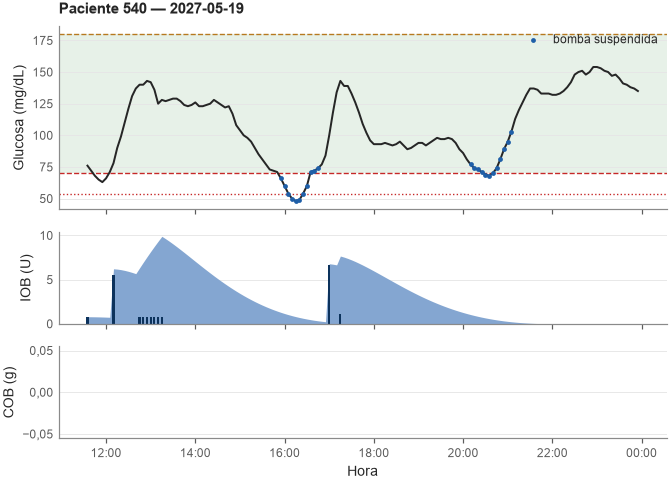

In [4]:
# Un día completo con las señales superpuestas.
dia = frame.loc[frame.pump_suspended > 0, "ts"].iloc[0].normalize()
sub = frame[(frame.ts >= dia) & (frame.ts < dia + pd.Timedelta(days=1))]

fig, axes = plt.subplots(3, 1, figsize=(FIG_WIDTH_FULL, 4.6), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1, 1]})

axes[0].plot(sub.ts, sub.value, color=ROLE["observado"], lw=1.3)
add_glycemic_bands(axes[0])
susp = sub[sub.pump_suspended > 0]
if len(susp):
    axes[0].scatter(susp.ts, susp.value, s=10, color=ROLE["modelo"], zorder=4,
                    label="bomba suspendida")
    axes[0].legend(loc="upper right")
axes[0].set_title(f"Paciente {p} — {dia.date()}")

axes[1].fill_between(sub.ts, sub.iob, color=RAMPS["azul"]["claro"], lw=0)
axes[1].bar(sub.ts, sub.bolus_dose, width=0.002, color=RAMPS["azul"]["oscuro"])
axes[1].set_ylabel("IOB (U)")

axes[2].fill_between(sub.ts, sub.cob, color=RAMPS["naranja"]["claro"], lw=0)
axes[2].set_ylabel("COB (g)")
axes[2].set_xlabel("Hora")
axes[2].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))

fig.tight_layout()
save_figure(fig, "02_dia_con_features")
plt.show()

## 3. Ventanas

Historia de 12 pasos (60 min) → objetivos a +6 (30 min) y +12 (60 min). Una ventana solo se
emite si **toda** su historia y **todos** sus objetivos caen dentro del mismo segmento.

In [5]:
ws = patient_windows(p, "train")
print(f"X: {ws.X.shape}   (ventanas, pasos de historia, features)")
print(f"y: {ws.y.shape}   horizontes: {ws.horizon_minutes} min")
print(f"features: {ws.feature_names}")

X: (11490, 12, 12)   (ventanas, pasos de historia, features)
y: (11490, 2)   horizontes: (30, 60) min
features: ['value', 'roc', 'iob', 'bolus_dose', 'basal_rate', 'pump_suspended', 'cob', 'carbs', 'hour_sin', 'hour_cos', 'is_imputed', 'sensor_jump']


In [6]:
# Cuánto se pierde por la segmentación, para los 12 pacientes.
rows = []
for pat in PATIENTS:
    cgm = load_cgm(pat, "train")
    w = patient_windows(pat, "train")
    teorico = len(cgm) - 12 - 12 + 1  # si la serie fuese continua
    rows.append({"patient": pat, "muestras": len(cgm), "ventanas": len(w),
                 "maximo_teorico": teorico, "retencion_%": 100 * len(w) / teorico})
ret = pd.DataFrame(rows)
print(ret.round(1).to_string(index=False))
print(f"\nRetención global: {100*ret.ventanas.sum()/ret.maximo_teorico.sum():.1f} %")

patient  muestras  ventanas  maximo_teorico  retencion_%
    559     10796     10027           10773         93.1
    563     12124     11882           12101         98.2
    570     10982     10578           10959         96.5
    575     11866     11148           11843         94.1
    588     12640     12402           12617         98.3
    591     10847     10439           10824         96.4
    540     11947     11490           11924         96.4
    544     10623     10149           10600         95.7
    552      9080      8582            9057         94.8
    567     10858      9757           10835         90.1
    584     12150     11527           12127         95.1
    596     10877     10463           10854         96.4

Retención global: 95.5 %


La segmentación cuesta en torno a un 5 % de las ventanas. Es un precio barato: la alternativa
es entrenar sobre saltos temporales que el modelo interpretaría como dinámica fisiológica real.

## 4. Comprobaciones de fuga de información

In [ ]:
tr, val = temporal_split(ws, val_fraction=0.2)

assert tr.ts.max() < val.ts.min()
print(f"[OK] train hasta {pd.Timestamp(tr.ts.max())}, validación desde {pd.Timestamp(val.ts.min())}")

solape = set(tr.ts.tolist()) & set(val.ts.tolist())
assert not solape
print(f"[OK] sin solape de instantes entre train y validación ({len(tr):,} / {len(val):,} ventanas)")

paso = np.abs(np.diff(ws.X[:, :, ws.feature_names.index("value")], axis=1))
limite = q.MAX_ROC_MG_DL_MIN * 5
print(f"Salto máximo dentro de una ventana: {paso.max():.0f} mg/dL en 5 min")
print(f"Pasos por encima del límite fisiológico ({limite:.0f} mg/dL): "
      f"{(paso > limite).sum():,} de {paso.size:,} ({100*(paso > limite).mean():.3f} %)")

[OK] train hasta 2027-06-23 18:30:00, validación desde 2027-06-23 18:35:00
[OK] sin solape de instantes entre train y validación (9,192 / 2,298 ventanas)
Salto máximo dentro de una ventana: 40 mg/dL en 5 min
Pasos por encima del límite fisiológico (25 mg/dL): 88 de 126,390 (0.070 %)


In [ ]:
from tfm.data.loaders import load_cgm
from tfm.data.parser import PATIENTS
from tfm.data.quality import flag_implausible_jumps, to_regular_grid

marcados = pasos = 0
maximo = 0.0
for p in PATIENTS:
    g = to_regular_grid(load_cgm(p, "train"))
    paso = g["value"].diff().abs()
    pasos += int(paso.notna().sum())
    marcados += int(flag_implausible_jumps(g).sum())
    maximo = max(maximo, float(paso.max()))
print(f"Saltos marcados: {marcados} de {pasos:,} pasos ({100 * marcados / pasos:.2f} %); "
      f"salto máximo {maximo:.0f} mg/dL en 5 min")

Saltos marcados: 595 de 134,351 pasos (0.44 %); salto máximo 112 mg/dL en 5 min


In [ ]:

scaler = WindowScaler().fit(tr)
val_s = scaler.transform(val)
print(f"Media de la glucosa escalada en validación: {val_s.X[:, :, 0].mean():+.3f}")
print("(distinta de 0 => el escalador no ha visto la validación)")

Media de la glucosa escalada en validación: +0.148
(distinta de 0 => el escalador no ha visto la validación)


## 5. Desbalance de la variable objetivo

Cuántas ventanas tienen un objetivo hipoglucémico. Es el número que justifica la *loss*
ponderada de la Fase 5.

In [10]:
summary = pd.read_parquet("../data/processed/windows_summary.parquet")
summary.set_index(["cohort", "patient", "split"]).round(2)

n_windows  n_features  pct_hypo_h30  pct_hypo_h60
cohort patient split                                                   
2018   559     train      10027          12          3.77          3.78
               test        2289          12          3.15          3.15
       563     train      11882          12          2.21          2.26
               test        2528          12          0.55          0.55
       570     train      10578          12          1.85          1.85
               test        2567          12          0.35          0.35
       575     train      11148          12          8.06          8.05
               test        2453          12          5.30          5.46
       588     train      12402          12          0.94          0.97
               test        2722          12          0.11          0.11
       591     train      10439          12          3.49          3.62
               test        2696          12          4.49          4.53
2020   540     train      11490          12          6.28          6.20
               test        2789          12          4.66          4.59
       544     train      10149          12          1.42          1.37
               test        2622          12          1.18          1.18
       552     train       8582          12          3.36          3.36
               test        2206          12          2.90          2.90
       567     train       9757          12          6.76          6.81
               test        2156          12          7.70          8.21
       584     train      11527          12          0.71          0.83
               test        2394          12          1.04          0.96
       596     train      10463          12          1.81          1.81
               test        2570          12          2.53          2.49

In [11]:
tr_w = summary[summary.split == "train"]
te_w = summary[summary.split == "test"]
print(f"Ventanas de entrenamiento: {tr_w.n_windows.sum():,}")
print(f"Ventanas de test:          {te_w.n_windows.sum():,}")
print(f"Features por ventana:      {tr_w.n_features.iloc[0]}")
print()
for h in (30, 60):
    col = f"pct_hypo_h{h}"
    pond = (tr_w[col] * tr_w.n_windows).sum() / tr_w.n_windows.sum()
    print(f"PH {h} min → objetivo hipoglucémico en el {pond:.2f} % de las ventanas de train "
          f"(rango por paciente: {tr_w[col].min():.2f} – {tr_w[col].max():.2f} %)")

Ventanas de entrenamiento: 128,444
Ventanas de test:          29,992
Features por ventana:      12

PH 30 min → objetivo hipoglucémico en el 3.35 % de las ventanas de train (rango por paciente: 0.71 – 8.06 %)
PH 60 min → objetivo hipoglucémico en el 3.37 % de las ventanas de train (rango por paciente: 0.83 – 8.05 %)


## 6. Modelo global: agrupación de pacientes y DataLoader

In [12]:
sets = [patient_windows(pat, "train") for pat in PATIENTS]
pool = concat_windows(sets)
pool_tr, pool_val = temporal_split(pool, val_fraction=0.2)

scaler = WindowScaler().fit(pool_tr)
loader = make_loader(scaler.transform(pool_tr), batch_size=256, shuffle=True)

xb, yb = next(iter(loader))
print(f"Conjunto global: {len(pool):,} ventanas de {len(PATIENTS)} pacientes")
print(f"Batch → X {tuple(xb.shape)}  y {tuple(yb.shape)}  dtype {xb.dtype}")
print(f"Sin NaN ni infinitos: {bool(np.isfinite(xb.numpy()).all() and np.isfinite(yb.numpy()).all())}")

Conjunto global: 128,444 ventanas de 12 pacientes
Batch → X (256, 12, 12)  y (256, 2)  dtype torch.float32
Sin NaN ni infinitos: True


In [13]:
# Referencia mínima: persistencia (predecir el último valor observado).
# No es la línea base de la Fase 3, solo un control de cordura de los objetivos.
ultimo = pool.X[:, -1, pool.feature_names.index("value")]
for i, h in enumerate(pool.horizon_minutes):
    rmse = np.sqrt(np.mean((pool.y[:, i] - ultimo) ** 2))
    print(f"Persistencia a {h:>2} min → RMSE {rmse:6.2f} mg/dL")

Persistencia a 30 min → RMSE  25.01 mg/dL
Persistencia a 60 min → RMSE  40.50 mg/dL


Persistencia: **25,0 mg/dL a 30 min y 40,5 a 60 min**, en el orden esperado según la literatura
del BGLP Challenge. Confirma que los objetivos están correctamente alineados con sus horizontes:
**si la alineación estuviese desplazada un paso, este número se dispararía**. Por eso se
comprueba aquí y no después de entrenar.

Cualquier modelo del TFM tiene que batir estas dos cifras con holgura; si no, no está
aprendiendo dinámica, solo copiando el último valor.

## 7. Conclusiones

- Pipeline completo de XML a tensores, reproducible con `python -m tfm.data.build_processed`.
- **128.444 ventanas de entrenamiento** y **29.992 de test**, 12 features, retención del 95,5 %
  tras la segmentación.
- Detectados y marcados los **saltos de recalibración del sensor** (0,43 % de los pasos, hasta
  112 mg/dL en 5 min) mediante la feature `sensor_jump`.
- Fuga de información descartada con cuatro comprobaciones explícitas (corte temporal, sin
  solape de instantes, sin saltos dentro de ventana, escalador ciego a la validación).
- Desbalance cuantificado: ~3,3 % de ventanas con objetivo hipoglucémico, con un factor 10 de
  variación entre pacientes.
- Persistencia (25,0 y 40,5 mg/dL) en el rango esperado → objetivos correctamente alineados.